**ELECTION FRAUD DETECTION USING MACHINE LEARNING**


**Problem Statement:**
 Election fraud can threaten the fairness and credibility of democratic processes. Traditional fraud detection methods mainly rely on electoral statistics and often overlook cybersecurity threats that may influence election outcomes. As election systems become increasingly digital, there is a need for a machine learning-based solution that can analyze both electoral and cyber-related indicators to effectively identify potential fraudulent activities.


**Objective**
 To develop a machine learning model that detects potential election fraud using Election Commission electoral data and cybersecurity-related indicators..


**Data Description:**

Source:https://www.kaggle.com/datasets/lukhilaksh/strategic-voting-machine

This dataset is a hybrid election fraud detection dataset that integrates election statistics, candidate attributes, constituency information, behavioral indicators, cybersecurity risk factors, and fraud-related variables. The dataset aims to support machine learning models for detecting fraudulent election activities and assessing election integrity risks.

**Election and Constituency Information**
Election_ID: Unique identifier of the election.
State:       State where the election is conducted.
Constituency_Code: Unique code assigned to a constituency.
Constituency_Name: Name of the constituency.
Round: Vote counting round number.
Last_Updated_Time: Timestamp of the latest vote count update.
Registered_Voters: Total registered voters in the constituency.

**Candidate Profile Features**
Candidate_Name: Name of the candidate.
Party: Political party affiliation.
Gender: Candidate gender.
Age: Candidate age.
Education: Highest educational qualification.
Criminal_Cases: Number of declared criminal cases.
Assets_Cr: Candidate assets in crores.
Liabilities_Cr: Candidate liabilities in crores.
Campaign_Spending_Cr: Campaign expenditure in crores.

**Social Influence and Popularity Features**
Social_Media_Followers: Number of social media followers.
Speech_Sentiment: Sentiment score derived from speeches.
Popularity_Score: Overall popularity metric.
Historical_Win_Rate: Historical election win percentage.

**Voting Statistics**
EVM_Votes: Votes obtained through Electronic Voting Machines.
Postal_Votes: Votes obtained through postal ballots.
Total_Votes: Total votes secured.
Vote_Percentage: Percentage share of total votes.
Voter_Turnout: Percentage of voters who cast votes.
Postal_Vote_Ratio: Ratio of postal votes to total votes.

**Constituency Characteristics**
Constituency_Volatility: Variation in historical voting patterns.
Independent_Candidate_Count: Number of independent candidates.
Urban_Voter_Ratio: Proportion of urban voters.
Rural_Voter_Ratio: Proportion of rural voters.

**Vote Trend Features**
Vote_Surge_Score: Measures sudden increases in vote counts.
Vote_Change_Per_Round: Vote change between successive counting rounds.
Late_Round_Surge: Indicates unusual vote growth during later rounds.
Time_Between_Updates_min: Time interval between vote count updates.
Suspicious_Timing_Index: Indicator of suspicious update timing patterns.

**Fraud and Anomaly Indicators**
Fraud_Risk_Score: Overall fraud risk assessment score.
Anomaly_Score: Statistical measure of unusual voting patterns.
Strategic_Manipulation_Score: Likelihood of strategic manipulation.
Sequential_Risk_Score: Risk derived from sequential vote patterns.
Fraud_Proxy_Duplicate: Proxy variable correlated with fraud behavior.

**Cybersecurity Features**
Bot_Activity_Flag: Indicates suspected bot activity.
Fake_News_Score: Impact score of misinformation campaigns.
Cyber_Attack_Risk: Estimated cyberattack risk level.
Booth_Capture_Risk: Probability of physical booth capture incidents.
Deepfake_Propagation_Score: Risk of deepfake content influencing voters.
Vote_Injection_Risk: Risk of unauthorized vote insertion.
Attack_Type: Type of attack identified.
Defense_Strategy: Mitigation strategy against attacks.
Adversarial_Pressure: Level of adversarial interference.
Strategic_Polarization_Index: Political polarization score.
Influence_Network_Strength: Strength of influence networks affecting voter behavior.

**Election Infrastructure Features**
EVM_Device_ID: Identifier of the voting machine.
Server_Delay_ms: Election server response delay in milliseconds.
Network_Failure_Count: Number of network failures recorded.
Power_Outage_Risk: Risk associated with power failures.
Noise Features

These variables are artificially generated for experimentation and feature selection evaluation:

Noise_Float_1
Noise_Float_2
Noise_Category
Correlated_Noise_Score
Target Variables
Election_Result: Election outcome (Won/Lost).
Fraud_Label: Fraud detection label (0 = No Fraud, 1 = Fraud).
Risk_Category: Risk classification (Low, Medium, High).


IMPORTING REQUIRED LIBRARIES


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,cross_val_score,StratifiedKFold,GridSearchCV,RandomizedSearchCV

DATA COLLECTION

In [5]:
path=kagglehub.dataset_download("lukhilaksh/strategic-voting-machine")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'strategic-voting-machine' dataset.
Path to dataset files: /kaggle/input/strategic-voting-machine


CONVERTING DATASET TO DATAFRAME

In [6]:
file = os.path.join(path, os.listdir(path)[0])
df=pd.read_csv(file)
pd.set_option('display.max_columns', None)
df

,Election_ID,State,Constituency_Code,Constituency_Name,Round,Last_Updated_Time,Candidate_Name,Party,Gender,Age,Education,Criminal_Cases,Assets_Cr,Liabilities_Cr,Campaign_Spending_Cr,Social_Media_Followers,Speech_Sentiment,Popularity_Score,Historical_Win_Rate,Registered_Voters,EVM_Votes,Postal_Votes,Total_Votes,Vote_Percentage,Vote_Surge_Score,Constituency_Volatility,Independent_Candidate_Count,Voter_Turnout,Urban_Voter_Ratio,Rural_Voter_Ratio,Postal_Vote_Ratio,Fraud_Risk_Score,Anomaly_Score,Strategic_Manipulation_Score,Bot_Activity_Flag,Fake_News_Score,Cyber_Attack_Risk,Booth_Capture_Risk,Deepfake_Propagation_Score,Suspicious_Timing_Index,Vote_Injection_Risk,Attack_Type,Defense_Strategy,Adversarial_Pressure,Strategic_Polarization_Index,Influence_Network_Strength,Vote_Change_Per_Round,Late_Round_Surge,Time_Between_Updates_min,Sequential_Risk_Score,EVM_Device_ID,Server_Delay_ms,Network_Failure_Count,Power_Outage_Risk,Noise_Float_1,Noise_Float_2,Noise_Category,Correlated_Noise_Score,Fraud_Proxy_Duplicate,Election_Result,Fraud_Label,Risk_Category
0,137591d6-2b7b-47af-8ed2-f68e1f5434f6,Bihar,C0008,Nagpur,5,2024-05-21T15:28:18.800054+05:53,Yochana Khurana,YSRCP,Male,57,Post-Graduate,3,0.78,0.03,0.12,5901,0.3338,0.5099,0.2708,128036,93376,5329,98705,77.09,0.1190,0.2176,4,0.7709,0.2458,0.7542,0.0540,0.4859,0.4962,0.5553,True,0.6083,0.9021,0.5294,0.7490,0.6461,0.1708,Booth Capture,Rapid Response Team,1.0000,0.7281,0.4246,0.0116,0.0358,49.7,0.4764,EVM-WG926MVF,NaN,6,0.2407,21.980,31.310,D,0.1434,0.4657,Won,1,High
1,96fb1c8e-c776-4f82-b883-509719f7dadf,Assam,C0317,Sambalpur,1,2024-04-20T02:42:43.430954+05:53,Zansi Tara,NCP,Male,53,Post-Graduate,0,37.18,13.34,NaN,2812,0.3863,0.5378,0.3747,148165,79747,2599,82346,55.58,0.1236,0.1326,7,0.5558,0.7384,0.2616,0.0316,0.4201,0.3934,0.4405,True,0.5507,0.5758,0.4016,0.7336,0.2760,0.1683,Vote Stuffing,Media Fact-Check,0.6439,0.4937,0.2489,-0.0495,0.0000,179.3,0.2238,EVM-IR725CLM,341.2,5,0.0965,94.401,76.622,B,0.3228,0.4280,Won,1,Medium
2,973a3ec0-a2cd-4161-bce9-f9592435f64c,Madhya Pradesh,C0027,Kolhapur,3,2024-05-07T18:43:18.086654+05:53,Falguni Gaba,Independent,Male,63,Post-Graduate,1,1.75,0.64,0.65,28718,0.6685,0.6436,0.4959,180260,96227,1719,97946,54.34,0.1361,0.1613,6,0.5434,0.3962,0.6038,0.0176,0.3194,0.1757,0.2581,False,0.2279,0.2289,0.4764,0.1133,0.1290,0.1677,Physical Intimidation,CCTV Deployment,0.5767,0.4126,0.2468,0.0010,0.0000,67.3,0.1412,EVM-LG661RLJ,250.2,2,0.2881,78.950,70.513,B,0.6605,0.1211,Won,0,Low
3,12135bca-2269-4aa6-b02e-843adfc1eb61,Gujarat,C0276,Bongaigaon,6,2024-05-26T16:25:47.797091+05:53,Radhika Hayer,CPM,Female,66,12th Pass,0,10.08,2.44,1.35,7890,0.9111,0.7059,0.4750,168024,68071,20903,88974,52.95,0.2319,0.3166,4,0.5295,0.1603,0.8397,0.2349,0.3429,0.3838,0.3488,True,0.3397,0.1793,0.3421,0.5050,0.4740,0.3142,Cyber Intrusion,AI Monitoring,0.9957,0.6684,0.1720,-0.0229,0.1203,26.1,0.3859,EVM-MH866ILY,257.3,1,0.0592,24.436,55.382,E,0.3970,0.1825,Won,0,Medium
4,12d37e71-d165-49fb-84cf-aea6081da715,Maharashtra,C0472,Gudivada,5,2024-05-21T17:56:21.420097+05:53,Ikbal Venkataraman,JDU,Male,55,Graduate,3,16.29,4.02,4.78,3741,0.5780,0.4753,0.0736,139651,84967,12370,97337,69.70,0.0471,0.2898,4,0.6970,0.3515,0.6485,0.1271,0.2288,0.2646,0.1655,False,0.1694,0.4090,0.3393,0.1438,0.5279,0.1523,Bot Network,AI Monitoring,0.8833,0.5204,0.3496,0.0557,0.0311,49.8,0.2413,EVM-VR643DOK,436.6,1,0.1000,70.571,35.088,E,0.0237,0.1079,Lost,0,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21995,eefe5bbe-0e04-4675-8788-64b0b64fa117,Tamil Nadu,C0378,Bidhannagar,4,2024-05-14T17:12:54.190794+05:53,Nirja Raghavan,Independent,Male,61,Graduate,0,0.58,0.15,0.16,2747,0.7641,0.5645,0.6241,221317,122327,23840,146167,66.04,0.0900,0.0485,4,0.6604,0.4831,0.5169,0.1631,0.3191,0.2853,0.3303,True,0.5057,0.3433,0.2

In [7]:
df.columns

Index(['Election_ID', 'State', 'Constituency_Code', 'Constituency_Name',
       'Round', 'Last_Updated_Time', 'Candidate_Name', 'Party', 'Gender',
       'Age', 'Education', 'Criminal_Cases', 'Assets_Cr', 'Liabilities_Cr',
       'Campaign_Spending_Cr', 'Social_Media_Followers', 'Speech_Sentiment',
       'Popularity_Score', 'Historical_Win_Rate', 'Registered_Voters',
       'EVM_Votes', 'Postal_Votes', 'Total_Votes', 'Vote_Percentage',
       'Vote_Surge_Score', 'Constituency_Volatility',
       'Independent_Candidate_Count', 'Voter_Turnout', 'Urban_Voter_Ratio',
       'Rural_Voter_Ratio', 'Postal_Vote_Ratio', 'Fraud_Risk_Score',
       'Anomaly_Score', 'Strategic_Manipulation_Score', 'Bot_Activity_Flag',
       'Fake_News_Score', 'Cyber_Attack_Risk', 'Booth_Capture_Risk',
       'Deepfake_Propagation_Score', 'Suspicious_Timing_Index',
       'Vote_Injection_Risk', 'Attack_Type', 'Defense_Strategy',
       'Adversarial_Pressure', 'Strategic_Polarization_Index',
       'Influence_Netw

DATA PREPROCESSING

In [8]:
df.info()#Provide information about teh dataset


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 62 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Election_ID                   22000 non-null  object 
 1   State                         22000 non-null  object 
 2   Constituency_Code             22000 non-null  object 
 3   Constituency_Name             22000 non-null  object 
 4   Round                         22000 non-null  int64  
 5   Last_Updated_Time             22000 non-null  object 
 6   Candidate_Name                22000 non-null  object 
 7   Party                         22000 non-null  object 
 8   Gender                        22000 non-null  object 
 9   Age                           22000 non-null  int64  
 10  Education                     22000 non-null  object 
 11  Criminal_Cases                22000 non-null  int64  
 12  Assets_Cr                     21337 non-null  float64
 13  L

**Data columns: 62 columns**
**Data rows :22000**
**Having null values as well in some columns**

**Last Updated Time lies in Object Format.To be converted to datetime format**

In [9]:
df['Last_Updated_Time']=pd.to_datetime(df['Last_Updated_Time'])


FINDING NULL VALUES

In [10]:
nulls=df.isnull().sum()
nulls[nulls>0]



,0
Assets_Cr,663
Liabilities_Cr,681
Campaign_Spending_Cr,1328
Speech_Sentiment,871
Vote_Surge_Score,458
Fake_News_Score,659
Deepfake_Propagation_Score,905
Attack_Type,8388
Defense_Strategy,6522
Adversarial_Pressure,464


Attack Type and Defence Strategy being null means no attack reported or No Defence Strategy used.So None values can be treated.So no need of filling null values


FILLING NULL VALUES


In [11]:
df["Attack_Type"].fillna("None",inplace=True)
df["Defense_Strategy"].fillna("None",inplace=True)
cat_column=df.select_dtypes(include="object").drop(columns=["Attack_Type","Defense_Strategy"])
num_colum=df.select_dtypes(include=["float64","int64"]).columns
for cols in cat_column:
  df[cols]=df[cols].fillna(df[cols].mode()[0])
for cols in num_colum:
  df[cols]=df[cols].fillna(df[cols].mean())
df.isnull().sum()

,0
Election_ID,0
State,0
Constituency_Code,0
Constituency_Name,0
Round,0
...,...
Correlated_Noise_Score,0
Fraud_Proxy_Duplicate,0
Election_Result,0
Fraud_Label,0


FINDING DUPLICATE VALUES


In [12]:
df.duplicated().sum()



np.int64(0)

**No duplicates found**

FINDING OUTLIERS


In [13]:
cols=np.array(df.select_dtypes(include=["float64","int64"]).columns)
fig, ax=plt.subplots(23, 2, figsize=(40,300))
count=0
for i in range(23):
   for j in range(2):
    if count < len(cols):
     sns.boxplot(y=df[cols[count]],ax=ax[i][j])
     ax[i][j].set_ylabel(cols[count],fontsize=10)
     ax[i][j].set_title("Box plot of"+cols[count],fontsize=40)
    count+=1
plt.show()

**Most Columns have outliers,like popularity score,Social Media influencers,liabilities_cr,campaign_spending score.But these features naturally have large values.And also we are targeting on fraud Detection,abnormal values should learn by models to predict the fraud.So keeeping outliers in the dataset**


ANALYSING SKEWNESS


In [14]:
fig,ax=plt.subplots(23,2,figsize=(40,300))
count=0
for i in range(23):
  for j in range(2):
    if count < len(cols):
      sns.histplot(data=df,x=cols[count],ax=ax[i][j],kde=True)
      ax[i][j].set_xlabel(cols[count])
      ax[i][j].set_title("Histogram of "+cols[count])
      count+=1
plt.show()


Observation:Most Columns have skewness.

DISPLAYING SKEWED COLUMNS


In [15]:
skewed_cols=df.skew(numeric_only=True).reset_index()
skewed_cols.columns=["Column","Skewness"]
skewed_cols

,Column,Skewness
0,Round,0.180176
1,Age,0.015059
2,Criminal_Cases,1.897262
3,Assets_Cr,11.695592
4,Liabilities_Cr,8.871685
5,Campaign_Spending_Cr,13.522386
6,Social_Media_Followers,13.446376
7,Speech_Sentiment,-0.026741
8,Popularity_Score,-0.131287
9,Historical_Win_Rate,0.125071


DISPLAYING HIGH SKEWED COLUMNS


In [16]:
skew=skewed_cols[skewed_cols["Skewness"] > 1]
skew_=skewed_cols[skewed_cols["Skewness"] < -1]
skew_cols=pd.concat([skew,skew_])
skew_cols

,Column,Skewness
2,Criminal_Cases,1.897262
3,Assets_Cr,11.695592
4,Liabilities_Cr,8.871685
5,Campaign_Spending_Cr,13.522386
6,Social_Media_Followers,13.446376
10,Registered_Voters,1.598330
11,EVM_Votes,1.776703
12,Postal_Votes,3.870523
13,Total_Votes,1.749992
21,Postal_Vote_Ratio,1.855639


**Columns Assets_cr,Liabilities_cr and campaign_spending ND social media followers having high skewness.So log transformation required**


PERFORMING LOG TRANSFORMATION


In [17]:
for i in skew_cols["Column"]:
    df[i]=np.log1p(df[i])

**Skewness has been reduced**


EXPLORATORY DATA ANALYSIS


In [19]:
df.describe()


,Round,Age,Criminal_Cases,Assets_Cr,Liabilities_Cr,Campaign_Spending_Cr,Social_Media_Followers,Speech_Sentiment,Popularity_Score,Historical_Win_Rate,Registered_Voters,EVM_Votes,Postal_Votes,Total_Votes,Vote_Percentage,Vote_Surge_Score,Constituency_Volatility,Independent_Candidate_Count,Voter_Turnout,Urban_Voter_Ratio,Rural_Voter_Ratio,Postal_Vote_Ratio,Fraud_Risk_Score,Anomaly_Score,Strategic_Manipulation_Score,Fake_News_Score,Cyber_Attack_Risk,Booth_Capture_Risk,Deepfake_Propagation_Score,Suspicious_Timing_Index,Vote_Injection_Risk,Adversarial_Pressure,Strategic_Polarization_Index,Influence_Network_Strength,Vote_Change_Per_Round,Late_Round_Surge,Time_Between_Updates_min,Sequential_Risk_Score,Server_Delay_ms,Network_Failure_Count,Power_Outage_Risk,Noise_Float_1,Noise_Float_2,Correlated_Noise_Score,Fraud_Proxy_Duplicate,Fraud_Label
count,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000,22000.000000
mean,3.689955,51.573545,0.725596,1.385347,0.651842,0.573717,9.688224,0.515570,0.561238,0.418132,11.797368,11.293209,8.574991,11.390037,67.367878,0.106607,0.231716,4.506955,0.673679,0.427959,0.572041,0.082331,0.308454,0.281648,0.301877,0.350510,0.404901,0.395864,0.341996,0.305575,0.162761,0.529941,0.423785,0.181342,0.000115,0.033855,3.828212,0.233350,5.553791,2.046773,0.182775,50.190101,50.004835,0.326545,0.276242,0.316818
std,1.979671,9.939530,0.783309,0.816202,0.582449,0.510395,1.521488,0.189531,0.104015,0.166254,0.498666,0.532526,1.110947,0.523138,10.300408,0.060389,0.154237,2.138410,0.103004,0.173898,0.173898,0.068198,0.090616,0.102149,0.103318,0.171167,0.156628,0.119803,0.250333,0.182615,0.063386,0.357229,0.187598,0.117084,0.032551,0.069730,0.744743,0.120186,0.476889,1.585809,0.093609,28.063469,14.717564,0.237584,0.113033,0.465246
min,1.000000,25.000000,0.000000,0.029559,0.000000,0.000000,4.615121,0.022800,0.178900,0.000000,10.596660,9.519295,2.079442,9.727943,35.000000,0.000300,0.000300,0.000000,0.350000,0.013700,0.040700,0.000100,0.052200,0.062900,0.015300,0.000000,0.082900,0.106600,0.000000,0.047400,0.041526,0.000000,0.041100,0.015184,-0.129400,0.000000,1.791759,0.001900,3.288402,0.000000,0.020195,0.001000,-12.890000,0.000000,0.000000,0.000000
25%,2.000000,45.000000,0.000000,0.746688,0.215111,0.190620,8.673385,0.376800,0.492000,0.298800,11.459918,10.932580,7.908755,11.035269,59.490000,0.059800,0.109900,3.000000,0.594900,0.297100,0.449800,0.033628,0.241000,0.196400,0.220200,0.207900,0.291175,0.306200,0.130000,0.154300,0.120269,0.116675,0.226800,0.086728,-0.021400,0.000000,3.346389,0.136000,5.255932,1.000000,0.109840,26.593500,40.563000,0.130150,0.197700,0.000000
50%,4.000000,52.000000,0.693147,1.266948,0.476234,0.431782,9.685456,0.515570,0.563650,0.413550,11.794749,11.294919,8.655302,11.390328,68.470000,0.101000,0.204200,4.000000,0.684700,0.421000,0.579000,0.063913,0.304500,0.270250,0.291200,0.300500,0.381350,0.388000,0.201200,0.211700,0.152120,0.663900,0.478000,0.148334,0.000115,0.000000,3.867026,0.217250,5.573294,2.000000,0.164667,50.190101,50.004835,0.310650,0.274650,0.000000
75%,5.000000,58.000000,1.386294,1.848455,0.889869,0.756665,10.717496,0.655900,0.633425,0.535325,12.137493,11.653244,9.344434,11.741741,75.260000,0.144400,0.327700,6.000000,0.752600,0.550200,0.702900,0.109661,0.369700,0.358900,0.378100,0.513900,0.499200,0.469925,0.625500,0.502600,0.184236,0.832700,0.581900,0.252392,0.021500,0.036332,4.347694,0.301900,5.844703,3.000000,0.238859,74.013000,59.431000,0.487300,0.353500,1.000000
max,7

ANALYSING TOP 5 CAMPAIGHN SPENDING CANDIDATES


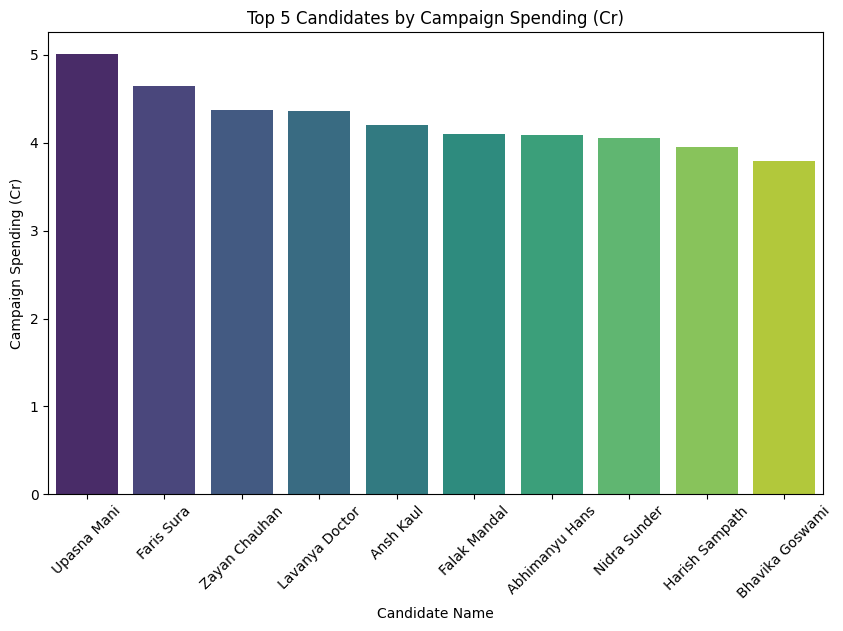

In [20]:
Cam_spend=df.groupby("Candidate_Name")["Campaign_Spending_Cr"].sum().sort_values(ascending=False).reset_index().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(data=Cam_spend, x="Candidate_Name", y="Campaign_Spending_Cr", palette="viridis")
plt.title("Top 5 Candidates by Campaign Spending (Cr)")
plt.xlabel("Candidate Name")
plt.ylabel("Campaign Spending (Cr)")
plt.xticks(rotation=45)
plt.show()

**Upasna Mani have spended more money as part of Campaign**


TOP 5 CANDIDATES HAVING MORE SOCIAL MEDIA FOLLOWERS


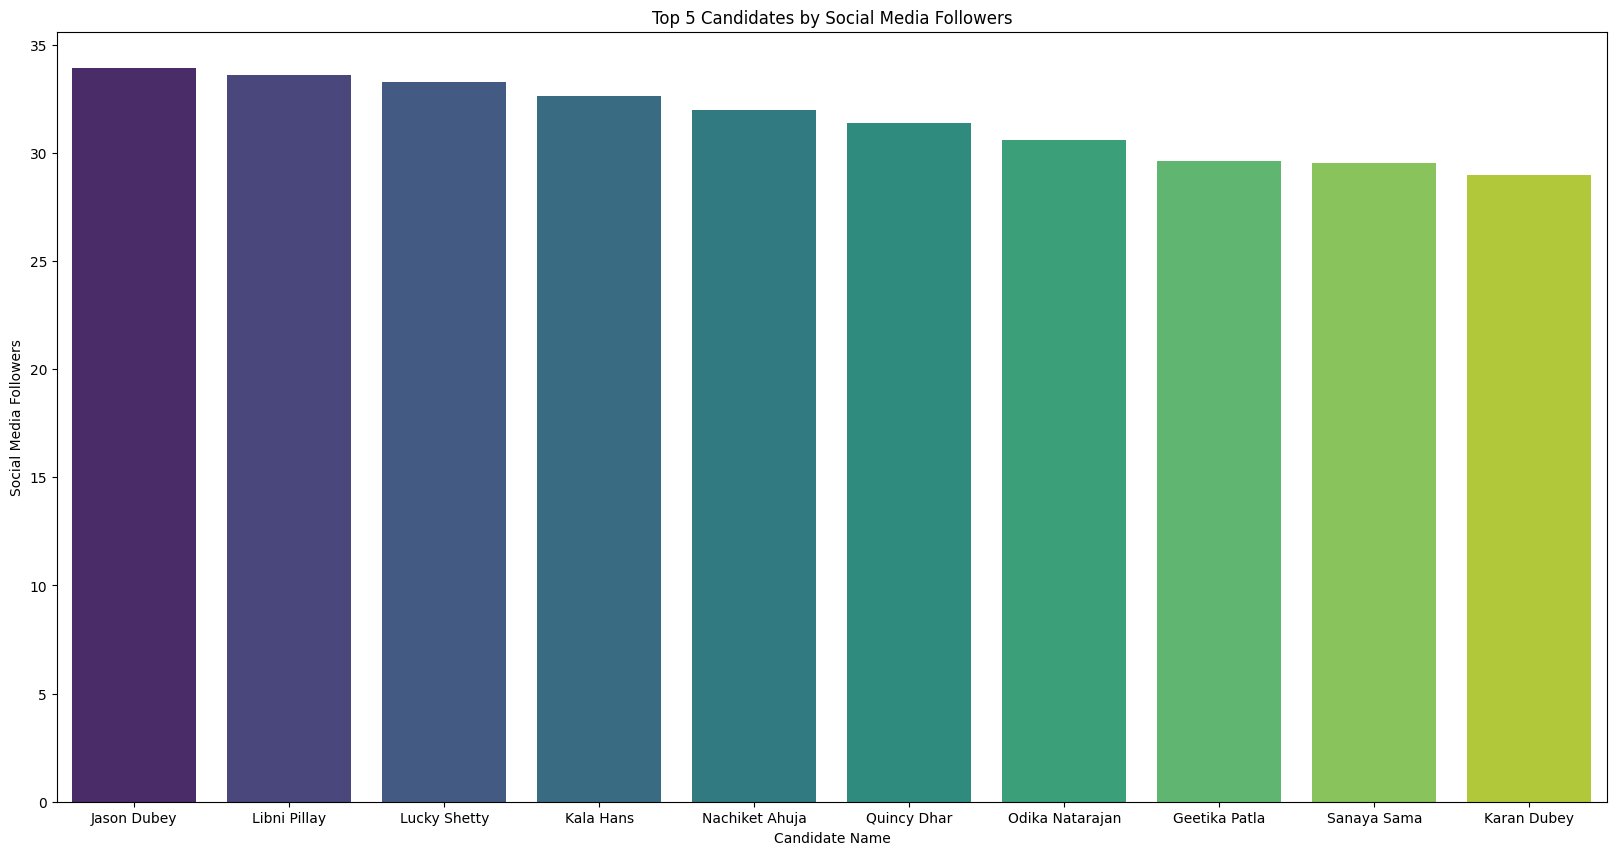

In [ ]:
soc_med=df.groupby("Candidate_Name")["Social_Media_Followers"].sum().sort_values(ascending=False).reset_index().head(10)
plt.figure(figsize=(20,10))
sns.barplot(data=soc_med,x="Candidate_Name",y="Social_Media_Followers",palette="viridis")
plt.title("Top 5 Candidates by Social Media Followers")
plt.xlabel("Candidate Name")
plt.ylabel("Social Media Followers")
plt.show()


**Jason Dubey have more social media followers**


FINDING CORRELATION BETWEEN FEATURES


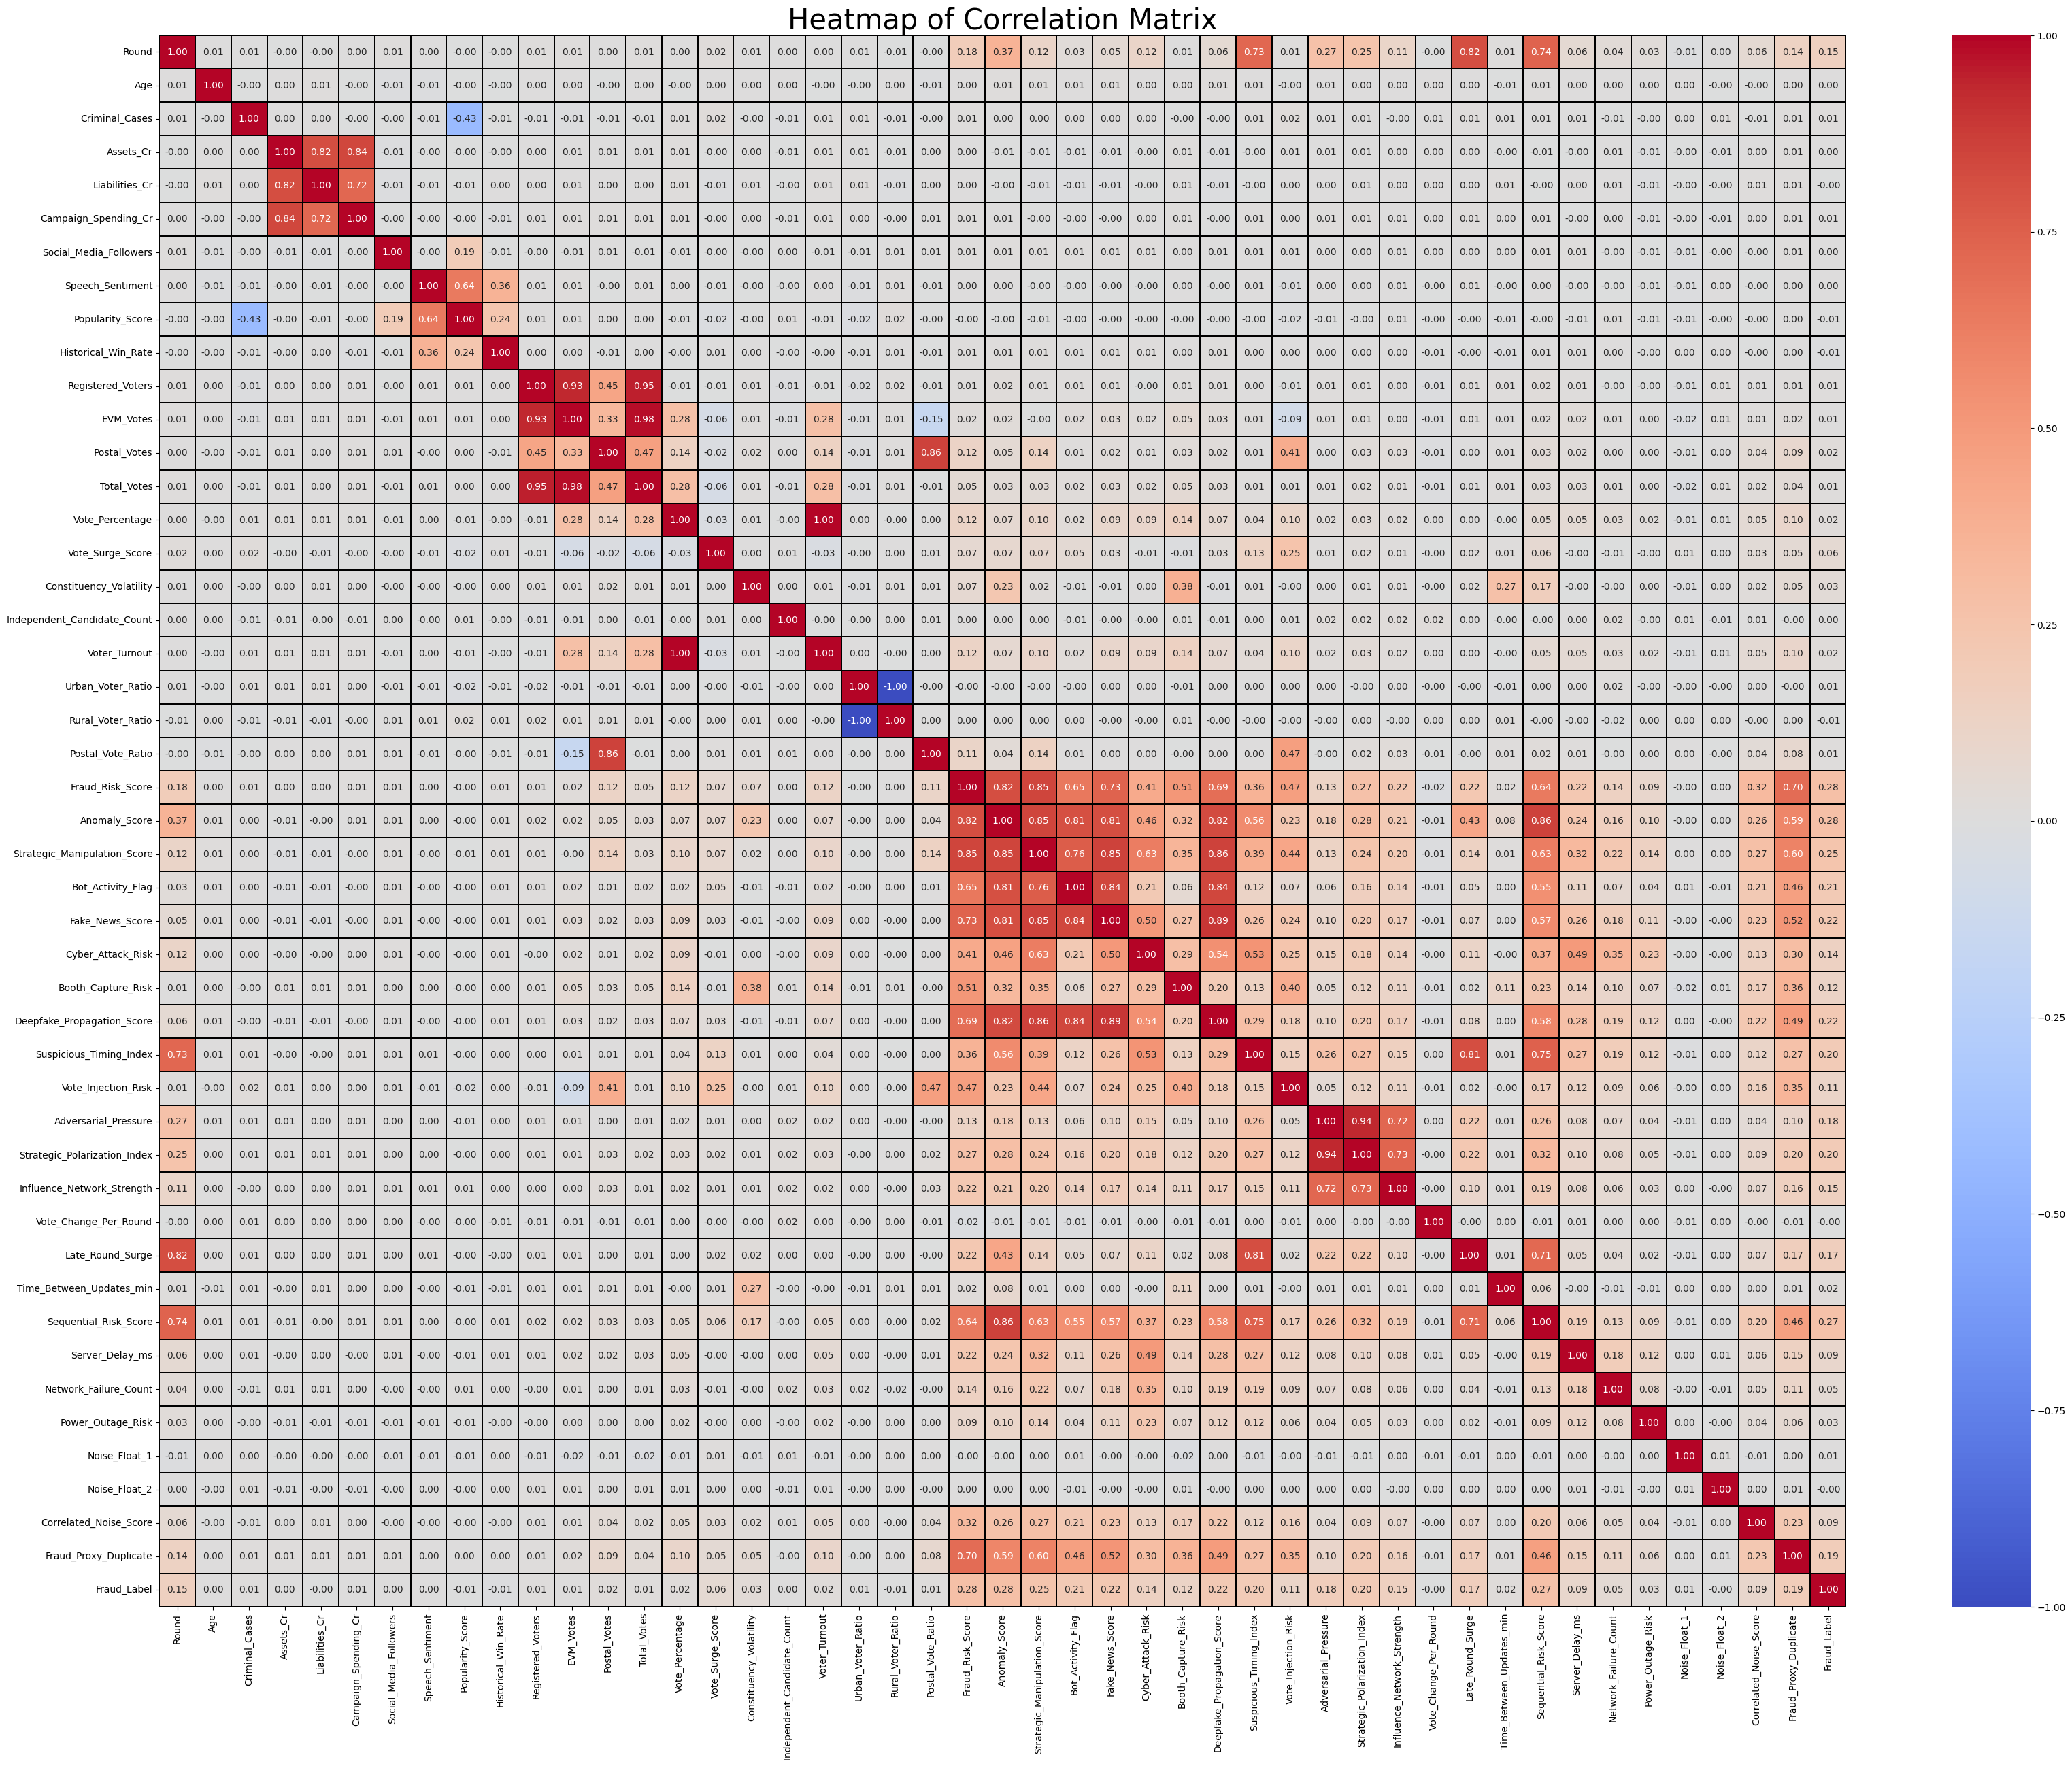

In [30]:
correlation=df.corr(numeric_only=True,method="spearman")
plt.figure(figsize=(40,30))
sns.heatmap(data=correlation,annot=True,fmt="0.2f",cmap="coolwarm",linewidth=1.2,linecolor="black")
plt.title("Heatmap of Correlation Matrix",fontsize=30)
plt.show()

**Correlated_Noise_Score,Fraud_Proxy_Duplicate,Sequential_risk-Score,Late_Round_surge,Influence_Network_Strength,Suspicious_Timing_index,Deep_fake_Propagation_score,Fake_News_score_Bot_Activity_Flag,Strategic_Manipulation_score,Anomaly_score,fraud_risk_score and round columns have positive correlation with target variable"fraudLabel"**


FEATURE ENGINEERING

Encoding Object Features

In [18]:
le=LabelEncoder()
for i in df.select_dtypes(include="object").columns:
  df[i]=le.fit_transform(df[i])

FEATURE SELECTION

In [19]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 62 columns):
 #   Column                        Non-Null Count  Dtype                    
---  ------                        --------------  -----                    
 0   Election_ID                   22000 non-null  int64                    
 1   State                         22000 non-null  int64                    
 2   Constituency_Code             22000 non-null  int64                    
 3   Constituency_Name             22000 non-null  int64                    
 4   Round                         22000 non-null  int64                    
 5   Last_Updated_Time             22000 non-null  datetime64[ns, UTC+05:53]
 6   Candidate_Name                22000 non-null  int64                    
 7   Party                         22000 non-null  int64                    
 8   Gender                        22000 non-null  int64                    
 9   Age                           22000 non

Columns should be removed:
 'Election_ID',
 'State',
 'Constituency_Code',
 'Constituency_Name',
 'Last_Updated_Time',
 'EVM_Device_ID'
 state

 These features are identifiers type,so irrelevant to the target variable

 Fraud_Risk_Score
 Anomaly_Score
 Strategic_Manipulation_Score
 Sequential_Risk_Score
 Fraud_Proxy_Duplicate


Eventhough these columns having high correlation with target variable,but it will give a unrealistic accuracy,as these features seems to be synthetically  created from Target columns

And also removing all synthetic features,beacause focusing on real world datas to predict the output


In [20]:

X = df[[
    'Round',
    'Constituency_Name',
    'Party',
    'Gender',
    'Age',
    'Education',
    'Criminal_Cases',
    'Assets_Cr',
    'Liabilities_Cr',
    'Campaign_Spending_Cr',
    'Social_Media_Followers',
    'Speech_Sentiment',
    'Popularity_Score',
    'Historical_Win_Rate',
    'Registered_Voters',
    'Total_Votes',
    'Postal_Votes',
    'EVM_Votes',
    'Vote_Percentage',
    'Vote_Surge_Score',
    'Constituency_Volatility',
    'Independent_Candidate_Count',
    'Voter_Turnout',
    'Urban_Voter_Ratio',
    'Rural_Voter_Ratio',
    'Postal_Vote_Ratio',
    'Anomaly_Score',
    'Bot_Activity_Flag',
    'Fake_News_Score',
    'Cyber_Attack_Risk',
    'Server_Delay_ms',
    'Vote_Change_Per_Round',
    'Late_Round_Surge',
    'Defense_Strategy',
    ]]
y=df["Fraud_Label"]
X.columns

Index(['Round', 'Constituency_Name', 'Party', 'Gender', 'Age', 'Education',
       'Criminal_Cases', 'Assets_Cr', 'Liabilities_Cr', 'Campaign_Spending_Cr',
       'Social_Media_Followers', 'Speech_Sentiment', 'Popularity_Score',
       'Historical_Win_Rate', 'Registered_Voters', 'Total_Votes',
       'Postal_Votes', 'EVM_Votes', 'Vote_Percentage', 'Vote_Surge_Score',
       'Constituency_Volatility', 'Independent_Candidate_Count',
       'Voter_Turnout', 'Urban_Voter_Ratio', 'Rural_Voter_Ratio',
       'Postal_Vote_Ratio', 'Anomaly_Score', 'Bot_Activity_Flag',
       'Fake_News_Score', 'Cyber_Attack_Risk', 'Server_Delay_ms',
       'Vote_Change_Per_Round', 'Late_Round_Surge', 'Defense_Strategy'],
      dtype='object')

FINDING K BEST FEATURES


In [21]:
from sklearn.feature_selection import SelectKBest,f_classif
selector=SelectKBest(score_func=f_classif,k=20)
X_new=selector.fit_transform(X,y)
feature_scores = pd.DataFrame({
'Feature': X.columns,
'Score': selector.scores_
})
print(feature_scores.sort_values('Score', ascending=False))

                        Feature        Score
26                Anomaly_Score  1952.448665
28              Fake_News_Score  1180.181419
27            Bot_Activity_Flag   975.509708
0                         Round   538.841007
29            Cyber_Attack_Risk   484.025363
32             Late_Round_Surge   459.608122
30              Server_Delay_ms   223.838608
19             Vote_Surge_Score    76.994480
20      Constituency_Volatility    27.671303
25            Postal_Vote_Ratio    12.673837
33             Defense_Strategy     6.480122
1             Constituency_Name     6.321104
16                 Postal_Votes     6.092709
15                  Total_Votes     3.360713
18              Vote_Percentage     3.188245
22                Voter_Turnout     3.188245
14            Registered_Voters     2.483053
5                     Education     2.348629
13          Historical_Win_Rate     1.436347
6                Criminal_Cases     1.307300
17                    EVM_Votes     1.186719
3         

**Removing columns having less score**

In [22]:
X.drop(columns=['Vote_Change_Per_Round','Registered_Voters','Historical_Win_Rate','Voter_Turnout','Criminal_Cases','Gender','Age','Education','Urban_Voter_Ratio','Rural_Voter_Ratio','Independent_Candidate_Count','Party','Liabilities_Cr','Social_Media_Followers','Campaign_Spending_Cr','Popularity_Score','Speech_Sentiment','Assets_Cr','EVM_Votes'],inplace=True)
X.columns

Index(['Round', 'Constituency_Name', 'Total_Votes', 'Postal_Votes',
       'Vote_Percentage', 'Vote_Surge_Score', 'Constituency_Volatility',
       'Postal_Vote_Ratio', 'Anomaly_Score', 'Bot_Activity_Flag',
       'Fake_News_Score', 'Cyber_Attack_Risk', 'Server_Delay_ms',
       'Late_Round_Surge', 'Defense_Strategy'],
      dtype='object')

SPLITTING DATA INTO TRAIN AND TEST


In [23]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


SPLITTING TEST DATA

In [24]:
X_test.shape
X_test1,X_test2,y_test1,y_test2=train_test_split(X_test,y_test,test_size=0.1,random_state=42,stratify=y_test)
print(X_test1.shape,X_test2.shape)

(3960, 15) (440, 15)


CHECKING IMBALANCE

In [25]:
y_dist=y_train.value_counts()
y_dist

,count
Fraud_Label,
0,12024
1,5576


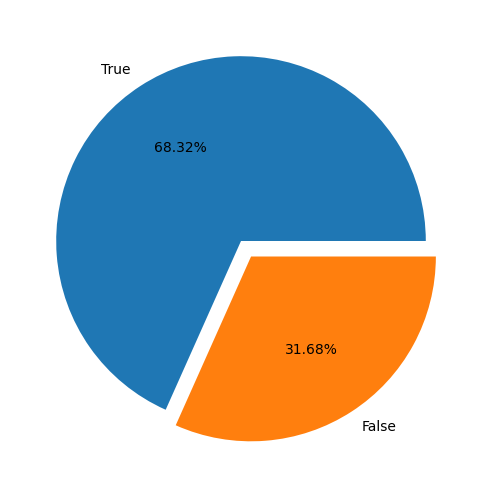

In [60]:
plt.figure(figsize=(10,6))
plt.pie(y_dist,labels=["True","False"],autopct="%.2f%%",explode=[0,0.1])
plt.show()

**Data seems unbalanced.60% True values and 30% false values.Needs to get it balanced.Borderline-SMOTE is best here**


RESAMBLING USING BORDERLINE SMOTE


In [26]:
from imblearn.over_sampling import BorderlineSMOTE
bsmote = BorderlineSMOTE(random_state=42)
X_resampled, y_resampled = bsmote.fit_resample(X_train, y_train)
print(y_resampled.value_counts())

Fraud_Label
0    12024
1    12024
Name: count, dtype: int64


FEATURE SCALING


In [27]:
scaler=StandardScaler()
Xtrain_scaled=scaler.fit_transform(X_resampled)
Xtest_scaled=scaler.transform(X_test1)

MODEL BULIDING


In [68]:
!pip install catboost -q
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier,AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,recall_score,precision_score,f1_score

models={"Logistic Regression":LogisticRegression(),
        "Decision Tree":DecisionTreeClassifier(random_state=42),
        "Random forest":RandomForestClassifier(random_state=42),
        "Support Vector Classifier":SVC(random_state=42),
        "KNN":KNeighborsClassifier(),
        "Naive Bayes":GaussianNB(),
        "XGBoost":XGBClassifier(random_state=42),
        "Gradient Boosting":GradientBoostingClassifier(random_state=42),
        "AdaBoost":AdaBoostClassifier(random_state=42),
        "CatBoost":CatBoostClassifier(random_state=42),
        "LightGBM":LGBMClassifier(random_state=42)
        }
matrics=pd.DataFrame(columns=["Model","Accuracy","Recall","Precision","F1Score"])
count=0
for name,model in models.items():
  model.fit(Xtrain_scaled,y_resampled)
  y_pred=model.predict(Xtest_scaled)
  accuracy = accuracy_score(y_test1, y_pred)
  recall = recall_score(y_test1, y_pred)
  precision = precision_score(y_test1, y_pred)
  f1 = f1_score(y_test1, y_pred)
  conf_matrix = confusion_matrix(y_test1, y_pred)
  recall=recall_score(y_test1,y_pred)
  precision=precision_score(y_test1,y_pred)
  conf_matrix=confusion_matrix(y_test1,y_pred)
  f1=f1_score(y_test1,y_pred)
  print(f"Model:{name}")
  print(f"Accuracy:{accuracy}")
  print(f"Recall:{recall}")
  print(f"Precision:{precision}")
  print(f"F1 Score:{f1}")
  print("\n")
  print(f"Confusion Matrix:\n{conf_matrix}")
  print("\n")
  if count < 11:
   matrics.loc[count]=[name,accuracy,recall,precision,f1]
   count+=1

Model:Logistic Regression
Accuracy:0.6406565656565657
Recall:0.5370517928286852
Precision:0.4445910290237467
F1 Score:0.4864669794298087


Confusion Matrix:
[[1863  842]
 [ 581  674]]


Model:Decision Tree
Accuracy:0.5797979797979798
Recall:0.4207171314741036
Precision:0.3604095563139932
F1 Score:0.38823529411764707


Confusion Matrix:
[[1768  937]
 [ 727  528]]


Model:Random forest
Accuracy:0.6656565656565656
Recall:0.3944223107569721
Precision:0.46742209631728043
F1 Score:0.4278305963699222


Confusion Matrix:
[[2141  564]
 [ 760  495]]


Model:Support Vector Classifier
Accuracy:0.6505050505050505
Recall:0.47410358565737054
Precision:0.45109931766489764
F1 Score:0.46231546231546233


Confusion Matrix:
[[1981  724]
 [ 660  595]]


Model:KNN
Accuracy:0.5934343434343434
Recall:0.49163346613545816
Precision:0.3882945248584015
F1 Score:0.4338959212376934


Confusion Matrix:
[[1733  972]
 [ 638  617]]


Model:Naive Bayes
Accuracy:0.6343434343434343
Recall:0.5689243027888446
Precision:0.44

MODEL EVALUATION


In [69]:
matrics=matrics.sort_values(ascending=False,by="Accuracy")
matrics

,Model,Accuracy,Recall,Precision,F1Score
2,Random forest,0.665657,0.394422,0.467422,0.427831
9,CatBoost,0.665152,0.433466,0.469370,0.450704
10,LightGBM,0.662879,0.435060,0.465870,0.449938
7,Gradient Boosting,0.656061,0.478884,0.459129,0.468799
6,XGBoost,0.651515,0.419920,0.446989,0.433032
3,Support Vector Classifier,0.650505,0.474104,0.451099,0.462315
8,AdaBoost,0.641162,0.565737,0.447667,0.499824
0,Logistic Regression,0.640657,0.537052,0.444591,0.486467
5,Naive Bayes,0.634343,0.568924,0.440469,0.496523
4,KNN,0.593434,0.491633,0.388295,0.433896


Based on accuracy,Random Forest Gives high values
Base on precision,
 and Accuracy,CatBoost,LGBM and Random_Forest, comparitively high values


CV AND HYPERPARAMETER TUNING


In [30]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)


CATBOOST TUNING


In [ ]:
cat = CatBoostClassifier(
    random_state=42)

param_cat = {
    'iterations': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'depth': [4, 6, 8, 10],
    'l2_leaf_reg': [1, 3, 5, 7, 9],
    'bagging_temperature': [0, 1, 3, 5],
    'border_count': [32, 64, 128, 254]
}

random_cat = RandomizedSearchCV(
    cat,
    param_cat,
    n_iter=50,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    random_state=42
)

random_cat.fit(Xtrain_scaled, y_resampled)
print(random_cat.best_params_,random_cat.best_score_)


0:	learn: 0.6477515	total: 87.3ms	remaining: 43.6s
1:	learn: 0.6191782	total: 157ms	remaining: 39.2s
2:	learn: 0.5987515	total: 222ms	remaining: 36.8s
3:	learn: 0.5848939	total: 286ms	remaining: 35.4s
4:	learn: 0.5739453	total: 353ms	remaining: 35s
5:	learn: 0.5657943	total: 418ms	remaining: 34.4s
6:	learn: 0.5556005	total: 483ms	remaining: 34.1s
7:	learn: 0.5497774	total: 550ms	remaining: 33.8s
8:	learn: 0.5462972	total: 617ms	remaining: 33.7s
9:	learn: 0.5407139	total: 684ms	remaining: 33.5s
10:	learn: 0.5355171	total: 751ms	remaining: 33.4s
11:	learn: 0.5305767	total: 816ms	remaining: 33.2s
12:	learn: 0.5265379	total: 885ms	remaining: 33.1s
13:	learn: 0.5220379	total: 952ms	remaining: 33.1s
14:	learn: 0.5196891	total: 1.02s	remaining: 32.9s
15:	learn: 0.5159077	total: 1.08s	remaining: 32.7s
16:	learn: 0.5127636	total: 1.17s	remaining: 33.1s
17:	learn: 0.5093778	total: 1.23s	remaining: 32.9s
18:	learn: 0.5061164	total: 1.29s	remaining: 32.7s
19:	learn: 0.5026399	total: 1.36s	remainin

LGBM TUNING


In [31]:
lgbm = LGBMClassifier(random_state=42)

param_lgbm = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 10, -1],
    'num_leaves': [15, 31, 63, 127],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_samples': [10, 20, 30, 50],
    'reg_alpha': [0, 0.01, 0.1, 1],
    'reg_lambda': [0, 0.01, 0.1, 1]
}

random_lgbm = RandomizedSearchCV(
    lgbm,
    param_lgbm,
    n_iter=50,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    random_state=42
)

random_lgbm.fit(Xtrain_scaled, y_resampled)
print(random_lgbm.best_params_,random_lgbm.best_score_)


[LightGBM] [Info] Number of positive: 12024, number of negative: 12024
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003988 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3074
[LightGBM] [Info] Number of data points in the train set: 24048, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further spli

RANDOM FOREST TUNING


In [72]:
rf = RandomForestClassifier(
    random_state=42
)

param_rf = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}

random_rf = RandomizedSearchCV(
    rf,
    param_rf,
    n_iter=10,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=2,
    random_state=42
)

random_rf.fit(Xtrain_scaled, y_resampled)
print(random_rf.best_params_,random_rf.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None, 'bootstrap': False} 0.7383265171199485


TRAINING FINAL MODELS WITH BEST PARAMS


In [74]:
models={
    "RandomForestClassifier": RandomForestClassifier(n_estimators=100,min_samples_split=5,min_samples_leaf=2,max_features='log2', max_depth=None,bootstrap= False,random_state=42),
    "LGBM Classifier": LGBMClassifier(subsample=0.8, reg_lambda=0, reg_alpha=0, num_leaves=127, n_estimators=300, min_child_samples=20, max_depth=10, learning_rate=0.05, colsample_bytree=0.8, random_state=42),
    "CatBoost": CatBoostClassifier(learning_rate=0.2, l2_leaf_reg=3, iterations=500, depth=10, border_count=254, bagging_temperature=0, random_state=42),
}

tuned_matrics=pd.DataFrame(columns=["Model","Accuracy","Recall","Precision","F1Score"])
count=0
for name,model in models.items():
  model.fit(Xtrain_scaled,y_resampled)
  y_pred=model.predict(Xtest_scaled)
  accuracy=accuracy_score(y_test1,y_pred)
  recall=recall_score(y_test1,y_pred)
  precision=precision_score(y_test1,y_pred)
  f1=f1_score(y_test1,y_pred)
  print(f"Model:{name}")
  print(f"Accuracy:{accuracy}")
  print(f"Recall:{recall}")
  print(f"Precision:{precision}")
  print(f"F1 Score:{f1}")
  print("\n")
  print(f"Confusion Matrix:\n{conf_matrix}")
  print("\n")
  if count < 11:
   tuned_matrics.loc[count]=[name,accuracy,recall,precision,f1]
   count+=1


Model:RandomForestClassifier
Accuracy:0.6696969696969697
Recall:0.39681274900398406
Precision:0.4747378455672069
F1 Score:0.4322916666666667


Confusion Matrix:
[[2079  626]
 [ 709  546]]


[LightGBM] [Info] Number of positive: 12024, number of negative: 12024
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003724 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3074
[LightGBM] [Info] Number of data points in the train set: 24048, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

In [76]:
tuned_matrics.sort_values(by="Accuracy", ascending=False)

,Model,Accuracy,Recall,Precision,F1Score
0,RandomForestClassifier,0.669697,0.396813,0.474738,0.432292
1,LGBM Classifier,0.669192,0.416733,0.475023,0.443973
2,CatBoost,0.636364,0.364143,0.415833,0.388275


Based on Accuracy,Random Forest give best performance
based on Precision,LGBM Classifier is th best
Based on Recall,LGBM Classifier,
Based on F1 Score,LGBM Classifier

CONCLUSION

LGBM Classifier can be onfirmed as best Model

FINAL MODEL

In [33]:
from lightgbm import LGBMClassifier
lgbm = LGBMClassifier(subsample=0.8,reg_lambda=0,reg_alpha=0,num_leaves=127,n_estimators=300,min_child_samples=20,max_depth=10,learning_rate=0.05,colsample_bytree= 0.8,random_state=42)
lgbm.fit(Xtrain_scaled,y_resampled)
y_pred=lgbm.predict(Xtest_scaled)

[LightGBM] [Info] Number of positive: 12024, number of negative: 12024
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007314 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3074
[LightGBM] [Info] Number of data points in the train set: 24048, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further spli

SAVING THE MODEL


In [34]:
import joblib
joblib.dump(lgbm,"LightGBM_model.pkl")

['LightGBM_model.pkl']

LOADING THE MODEL

In [35]:
joblib.load("LightGBM_model.pkl")

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.05, max_depth=10,
               n_estimators=300, num_leaves=127, random_state=42, reg_alpha=0,
               reg_lambda=0, subsample=0.8)

TEST WITH UNSEEN DATA

In [39]:
X_sample = X_test2.sample(5, random_state=42)
predictions = lgbm.predict(X_sample)
Result=pd.DataFrame({"Actual":y_test2.loc[X_sample.index],"Predicted":predictions})
Result

,Actual,Predicted
6,0,0
6307,1,0
20771,0,0
1321,0,0
8689,0,0


CONCLUSION

Model predicted all Non Fraud as Non Fraud and 1 Fraud as Non Fraud


The developed machine learning model achieved an accuracy of 66% on unseen test data, indicating a moderate ability to distinguish between the target classes.

As most of the cyberRelated Features are synthetically created,hence the ability of model to learn the real patterns has decreased

FUTURE WORK

This study primarily focuses on election fraud detection using election-related and cybersecurity-related features. Future research can incorporate additional data sources such as social media analytics, misinformation monitoring, sentiment analysis, and voter behavior patterns. These features may enhance the predictive capability and robustness of fraud detection models.

Furthermore, the current dataset contains a significant number of synthetic values generated to help the model learn underlying fraud patterns effectively. Future studies can utilize more comprehensive real-world election and cybersecurity datasets obtained from sources such as election commissions, cybersecurity incident reports, and public governance databases.

The use of real-world data may improve the model's generalizability, reliability, and predictive performance in practical election monitoring scenarios.
